In [1]:
# Code imports
from lib.opt_types import *
from lib.utils import *

# Image inpainting with proximal methods - 30 points + 2 bonus points

Image in-painting consists of reconstructing the missing parts of an image from a given incomplete image.

By exploiting some prior knowledge on the image, it is possible to in-paint images that have a large portion of their pixels missing. In this part of the homework, we are going to study different methods to achieve this goal.

We consider a subsampled image $\mathbf{b} = \mathbf{P}_{\Omega} \mathbf{x}$, where $\mathbf{P}_{\Omega} \in \mathbb{R}^{n \times p}$ is an operator that selects only few, $n \ll p := m^2$, pixels from the vectorized image $\mathbf{x} \in \mathbb{R}^p$. Our goal is to reconstruct the original image $\mathbf{x}$.

### Prior knowledge

Image inpainting is impossible without having some prior knowledge on the structure of the true image $\mathbf{x}$. 

We will explore and compare the following prior assumptions we can make on the true image: 
>  **Assumption**: There exists a orthonormal basis $\mathbf{W} \in \mathbb{R}^{p\times p}$ such that $\mathbf{x}$ can be sparsely represented in that basis, i.e, $\mathbf{W} \mathbf{x}$ is a vector with few non-zero coefficients. Writing $\boldsymbol\alpha=\mathbf W\mathbf x$, we have $\mathbf x=\mathbf W^\top\boldsymbol\alpha$. We promote sparsity by penalizing $\|\boldsymbol\alpha\|_1$, a convex surrogate for the number of nonzero coefficients. We assume that this basis is known and corresponds to the _wavelet basis_. Under this assumption, the reconstruction problem corresponds to solving the following optimization problem:
$$
\min_{\mathbf{\alpha} \in \mathbb{R}^{p}} \underbrace{ \frac{1}{2}\|\mathbf{b} - \mathbf{P}_{\Omega} \mathbf{W}^T\mathbf{\alpha} \|_2^2}_{f_{\ell_1}(\mathbf{\alpha})} + \underbrace{\lambda_{\ell_1} \|\mathbf{\alpha}\|_1}_{g_{\ell_1}(\mathbf{\alpha})},
$$
where $\lambda_{\ell_1}$ is a coefficient we will need to choose.



# PART 1: Optimizing with an $\ell_1$ norm regularization

The optimization problem we are looking to solve have an objective function of the form:
$$
	 f(\mathbf{x}) + g(\mathbf{x}).
$$

These types of objectives are referred to as _composite objectives_ where one term, $f$, is smooth and differentiable and the other term $g$ is non-differentiable.

---

## Code structure:

Recall that we have been working with the `Function` type so far. We will augment this type to represent functions that are not differentiable:

- Given a `Function` `g` you can obtain a subgradient at a point `x` by calling `g.subgrad(x)`.

Moreover, since we are dealing with _composite_ problems with a an objective function that can be written `f + g`, we define the `CompositeFunction` type defined as
```python
@dataclass
class CompositeFunction:
    f: Function
    g: Function
```

The iterative schemes you will implement will receive a composite function that they can unpack as follows:

```python
def state_update(composite_function, state):
    f, g = composite_function

```

#### Question 1: (5 point)

A first approach to solve a non-smooth optimization problem can be to turn to subgradients. Review slide 42-44 of Lecture 6, and implement `SubG` with $\alpha_k = \frac{0.1}{\sqrt{k}}$, starting the counter at $k=1$.

In [2]:
@dataclass
class SubG_state(OptState):
    x_k: Vector
    k: int  # iteration counter, starts at 1 (needed for the step size 0.1 / sqrt(k))

In [3]:
def SubG_update(composite_function, state):
    f, g = composite_function
    x_k, k = state
    # Moreau-Rockafellar: d_k = grad f(x_k) + (a subgradient of g at x_k) is a subgradient of f + g at x_k
    d_k = f.grad(x_k) + g.subgrad(x_k)
    alpha_k = 0.1 / np.sqrt(k)
    return SubG_state(x_k=x_k - alpha_k * d_k, k=k + 1)

def SubG_initialize(composite_function, x_zero):
    return SubG_state(x_k=x_zero, k=1)

In [4]:
SubG = OptAlgorithm(name="SubG", init_state=SubG_initialize, state_update=SubG_update)

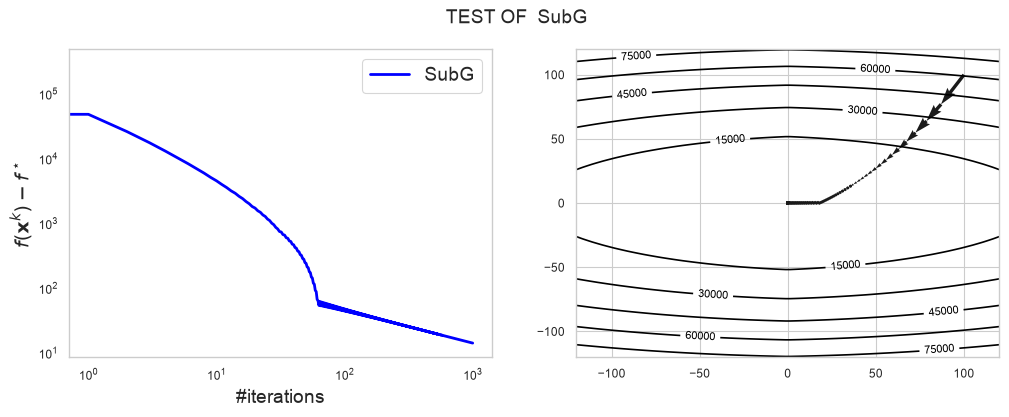

In [5]:
test_composite(SubG)


---

Another, more efficient approach, as we saw in Lecture 8, is to minimize such a function by using proximal gradient algorithms, provided that $g$ is _proximable_ (i.e., its proximal operator is efficient to evaluate). We recall the proximal operator of $g$ as the solution to the following convex problem:
$$
\mathrm{prox}_g(\mathbf{z}) := \mathrm{arg}\min_{\mathbf{y}\in\mathbb{R}^d}\{ g(\mathbf{y}) + \frac{1}{2}\Vert\mathbf{y} - \mathbf{z}\Vert_2^2\}.
$$

#### Question 2 (2 points)

Given $g_{\ell_1}: \mathbb{R}^p \rightarrow \mathbb{R}, \; g_{\ell_1}(\mathbf{x}) :=  \beta \|\mathbf{x}\|_1$ with $\beta\geq0$, show that its proximal function can be written as
    $$
    \mathrm{prox}_{\gamma g_{\ell_1}}(\mathbf{z}) = \max(|\mathbf{z}|-\beta \gamma,0) \circ \mathrm{sign}(\mathbf{z}), \; \text{for any }\mathbf{z} \in \mathbb{R}^p,\; \gamma \in \mathbb{R}_+
    $$
			where the operators $\max$, $\mathrm{sign}$ and $\lvert \cdot \lvert$ are applied coordinate-wise to the vector $\mathbf{z}$ and $\circ$ stands for $(\mathbf{x} \circ \mathbf{y})_i = x_i y_i$. Such a regularizer imposes sparsity on the solutions.


**Answer to Question 2**

Fix $\gamma \ge 0$ and $\beta \ge 0$, and set $\tau := \beta\gamma \ge 0$. By definition,
$$
\mathrm{prox}_{\gamma g_{\ell_1}}(\mathbf z)=\arg\min_{\mathbf y\in\mathbb R^p}\Big\{\gamma\beta\|\mathbf y\|_1+\tfrac12\|\mathbf y-\mathbf z\|_2^2\Big\}
=\arg\min_{\mathbf y\in\mathbb R^p}\ \sum_{i=1}^p \underbrace{\Big(\tau |y_i|+\tfrac12 (y_i-z_i)^2\Big)}_{=:\ \varphi_i(y_i)} .
$$

**The problem separates:** The objective is a sum of functions $\varphi_i$, each depending on a single coordinate $y_i$ only. Hence a vector $\mathbf y^\star$ minimizes the sum if and only if every $y_i^\star$ minimizes its own $\varphi_i$ (the coordinates can be chosen independently). It therefore suffices to solve the scalar problem $\min_{y\in\mathbb R}\varphi(y)$, with $\varphi(y)=\tau|y|+\tfrac12(y-z)^2$ and $z\in\mathbb R$.

**Existence and uniqueness:** $\varphi$ is the sum of the convex function $\tau|\cdot|$ and of the $1$-strongly convex function $\tfrac12(\cdot-z)^2$ (Its second derivative is 1 everywhere, so it curves upward at a rate of at least 1 everywhere.), so it is strongly convex, hence it has exactly one minimizer $y^\star$. Whatever candidate we find that satisfies the optimality condition below is therefore *the* proximal point.

**Optimality condition:** $\varphi$ is convex, so by the lemma of Lecture 6 (slide 42), $y^\star$ is a global minimizer iff $0\in\partial\varphi(y^\star)$. By the Moreau–Rockafellar theorem (same slide) $\partial\varphi=\tau\,\partial|\cdot|+\nabla\big(\tfrac12(\cdot-z)^2\big)$ (the quadratic is differentiable, so its subdifferential is just its gradient, slide 40). The condition reads:

$y^\star$ is a global minimizer iff
$$
 \quad 0\in \tau\,\partial|y^\star| + (y^\star - z)\quad\Longleftrightarrow\quad z-y^\star\in\tau\,\partial|y^\star| .
$$

We note that $\partial|y|=\{\mathrm{sign}(y)\}$ for $y\neq 0$ and $\partial|0|=[-1,1]$ (slide 41).

**Case analysis:** We wish to find the expression of $y^\star$ that satisfies the above condition for any fixed $z\in\mathbb R$. The three cases below cover all $z\in\mathbb R$ and are mutually exclusive:

* **$z>\tau$.** Try $y^\star>0$: then $\partial|y^\star|=\{1\}$, so $z-y^\star=\tau$, i.e. $y^\star=z-\tau$, which is indeed $>0$. The condition holds, so by uniqueness $y^\star=z-\tau=(|z|-\tau)\,\mathrm{sign}(z)$.
* **$z<-\tau$.** Try $y^\star<0$: then $\partial|y^\star|=\{-1\}$, so $z-y^\star=-\tau$, i.e. $y^\star=z+\tau<0$. The condition holds, so by uniqueness, $y^\star=z+\tau=-(|z|-\tau)=(|z|-\tau)\,\mathrm{sign}(z)$.
* **$|z|\le\tau$.** Try $y^\star=0$: the condition becomes $z\in\tau[-1,1]=[-\tau,\tau]$, which is true. So  by uniqueness, $y^\star=0$.

**Unify:** In the first two cases $|z|-\tau>0$ and in the third $|z|-\tau\le 0$. In all three cases
$$
y^\star=\max(|z|-\tau,0)\,\mathrm{sign}(z).
$$
(For $\tau=0$ this gives $y^\star=z$, as it should, since the objective is then just $\tfrac12(y-z)^2$.)

Applying this coordinate-wise (Step 1) and substituting back $\tau=\beta\gamma$:
$$
\boxed{\ \mathrm{prox}_{\gamma g_{\ell_1}}(\mathbf z)=\max(|\mathbf z|-\beta\gamma,\,0)\circ\mathrm{sign}(\mathbf z)\ }
$$
This is the *soft-thresholding* operator of Lecture 7 (the $\ell_1$, with $\lambda=\beta\gamma$). It shrinks every coordinate towards $0$ by $\beta\gamma$ and sets to exactly $0$ all coordinates with $|z_i|\le\beta\gamma$.

#### Question 3 (1 point)
 Fill in the function `l1_prox` with the proximal operator of $g_{\ell_1}$.

In [6]:
def l1_prox(gamma, z, beta):
    # soft-thresholding at level beta * gamma, applied coordinate-wise
    return np.sign(z) * np.maximum(np.abs(z) - beta * gamma, 0.0)

#### Question 4 (4 points)

From here on, in order to speed-up the convergence of the optimization, let's assume that the function $f$ has been made to be $\mu$-strongly convex by the addition of an $\ell_2$ regularization term to the function $f$, while the $\ell_1$ term, $g$, has remained unchanged. As such, we must now utilize the strong-convexity versions of the composite optimization algorithms.

Using the information in Lecture 7 slide 21 fill in the codes of the method $\text{ISTA}_\mu$. In the provided quadratic test, $\beta=30$. Use `g.prox(alpha, z)` to apply the proximal operator of the supplied regularizer, including its weight.

In [7]:
@dataclass
class ISTA_state(OptState):
    x_k: Vector
    k: int
    alpha: float

In [8]:
def ISTA_update(composite_function, state):
    f, g, = composite_function
    x_k, k, alpha = state
    next_x_k = g.prox(alpha, x_k - alpha * f.grad(x_k))
    return ISTA_state(next_x_k, k+1, alpha)

def ISTA_initialize(composite_function, x_zero):
    f,g = composite_function
    L_f = f.lips_grad
    mu = f.strng_cvx
    # optimal constant step size for a mu-strongly convex f with L_f-Lipschitz gradient (Lecture 7, slide 21)
    alpha = 2.0 / (L_f + mu)
    return ISTA_state(x_zero, 1, alpha)

In [9]:
ISTA = OptAlgorithm(name="ISTA", init_state= ISTA_initialize, state_update=ISTA_update)

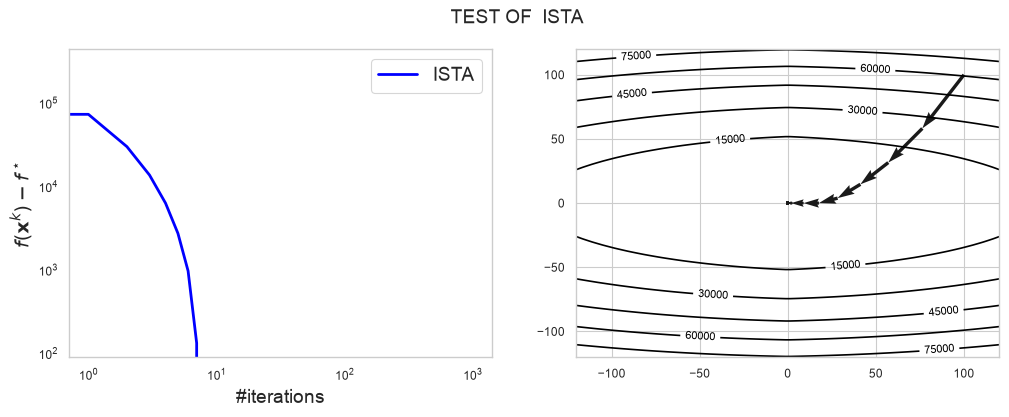

In [10]:
test_composite(ISTA, prox=l1_prox)


#### Question 5  (7 points)

Using the information in Lecture 7 slide 21 fill in the codes of the method $\text{FISTA}_\mu$.

In [11]:
@dataclass 
class FISTA_state(OptState):
    x_k: Vector
    y_k: Vector  # extrapolated point at which the gradient is evaluated
    k: int
    alpha: float
    cf: float

In [12]:
def FISTA_update(composite_function, state):
    f, g, = composite_function
    x_k, y_k, k, alpha, c_f = state
    beta_mom = (np.sqrt(c_f) - 1.0) / (np.sqrt(c_f) + 1.0)   # constant momentum weight
    next_x_k = g.prox(alpha, y_k - alpha * f.grad(y_k))
    next_y_k = next_x_k + beta_mom * (next_x_k - x_k)

    return FISTA_state(next_x_k, next_y_k, k + 1, alpha, c_f)

def FISTA_initialize(composite_function, x_zero):
    f, g, = composite_function
    L_f = f.lips_grad
    mu = f.strng_cvx
    alpha = 1 / L_f #optimal constant step size
    c_f = L_f / mu  #condition number
    return FISTA_state(x_zero, x_zero, 1, alpha, c_f) #we initialize y_0 = x_0

In [13]:
FISTA = OptAlgorithm(name="FISTA", init_state= FISTA_initialize, state_update=FISTA_update)

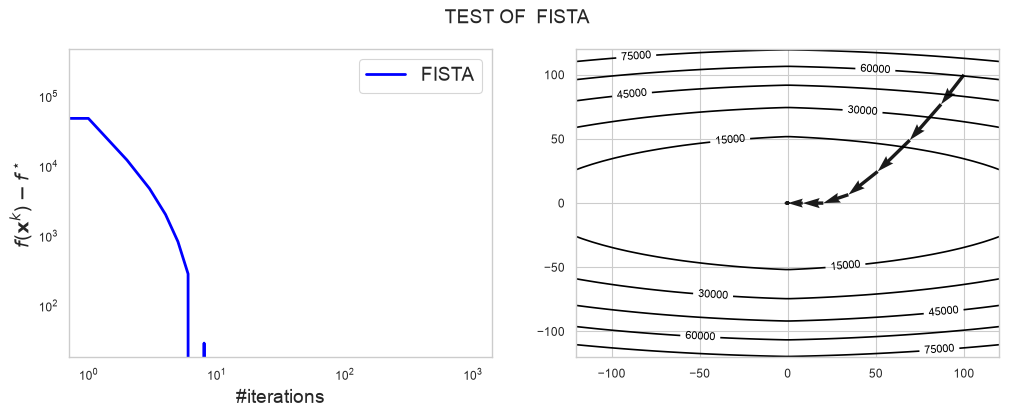

In [14]:
test_composite(FISTA, prox=l1_prox)


#### Question 6  (2 points)

Compare the convergence rates of the three methods and analyze whether the observed results align with their theoretical bounds.

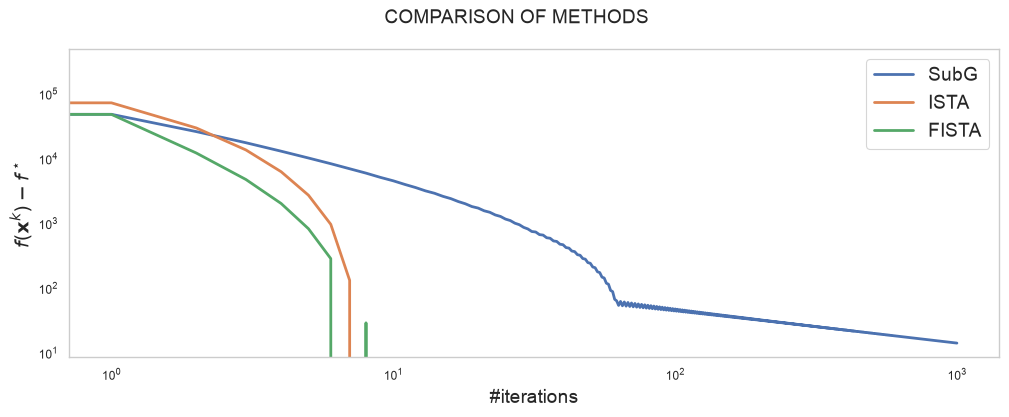

In [15]:
list_of_methods = [SubG, ISTA, FISTA]
compare_composite(list_of_methods, prox=l1_prox)


**Answer to Question 6.**

**In theory,**

| Method | Bound | Source |
|---|---|---|
| SubG | $\min_{i\le k}F(\mathbf x^i)-F^\star=O(1/\sqrt k)$ | L6, slide 44 |
| ISTA $_\mu$ | $F(\mathbf x^k)-F^\star\le\frac{L_f}{2}\,\omega^k\|\mathbf x^0-\mathbf x^\star\|^2$, $\ \omega=\big(\frac{c_f-1}{c_f+1}\big)^2=(9/11)^2\approx0.669$ | L7, slide 22 |
| FISTA $_\mu$ | $F(\mathbf x^k)-F^\star\le\frac{L_f+\mu}{2}\,\omega_f^{\,k}\|\mathbf x^0-\mathbf x^\star\|^2$, $\ \omega_f=1-\sqrt{\mu/L_f}\approx0.684$ | L7, slide 22 |

SubG is sublinear, while ISTA $_\mu$ and FISTA $_\mu$ are linear (complexity $O(\kappa\log\varepsilon^{-1})$ and $O(\sqrt\kappa\log\varepsilon^{-1})$ respectively, slide 23), so we expect them to beat SubG by far.


**In practice,** 

The plot shows the error $e_k:=F(\mathbf x^k)-F^\star$ against the iteration $k$, with *both* axes in log scale. Two facts are used below.
* If $e_k\approx C\,k^{-p}$ then $\log e_k=\log C-p\log k$, which is a straight line of slope $-p$ in a log–log plot. So a rate $O(1/\sqrt k)$ means a line of slope $-\tfrac12$.
* If $e_k\le C\,\omega^k$ with $\omega<1$ (linear rate), then $\log e_k\le\log C+k\log\omega$: the error decreases by a constant *factor* $\omega$ at every iteration, so in a log–log plot the curve bends downward faster and faster, and it is much below any straight line.

**1) Setting:** $F=f+g$, $f=\tfrac12\mathbf x^\top\mathbf M\mathbf x$, $\mathbf M=\mathrm{diag}(1,\dots,10)$, $g=30\|\cdot\|_1$, $\mathbf x^0=100\cdot\mathbf 1$.
* $\nabla^2f=\mathbf M$ has eigenvalues $1,\dots,10$, hence $\mu=1$ (smallest), $L_f=10$ (largest), and condition number $\kappa=L_f/\mu=10$.
* $\nabla f(\mathbf 0)=\mathbf 0$ and $\partial g(\mathbf 0)=[-30,30]^{10}\ni\mathbf 0$, so $\mathbf 0\in\nabla f(\mathbf 0)+\partial g(\mathbf 0)$, which is the optimality condition (Lecture 6, slide 42). It is the unique minimizer because $F$ is strongly convex ($f$ is $\mu$-strongly convex, $g$ is convex). So $\mathbf x^\star=\mathbf 0$, $F^\star=0$, and $e_k=F(\mathbf x^k)$. Note also $F(\mathbf x)\ge30\|\mathbf x\|_1$, so $F(\mathbf x)=0$ iff $\mathbf x=\mathbf 0$.

**2) Observations:**

* **SubG is by far the slowest and follows $1/\sqrt k$.** The error decreases quickly at first, when the coordinates are far from $0$, and then flattens. On the log–log plot, the end of the curve is a straight line of slope $\approx-\tfrac12$ (least-squares fit), i.e. error $\approx C/\sqrt k$, as predicted.

* **$ISTA_\mu$ and $FISTA_\mu$ are much faster, as expected from their linear rates.** They reach $F^\star=0$ exactly after a few iterations (the curves leave the log axis), while SubG is still far from it after 1000 iterations. FISTA is slightly ahead of ISTA, thanks to the momentum term.

* **They are even better than the bounds.** A bound of the form $C\omega^k$ is never exactly $0$, yet the true error is. This is because the prox of $\|\cdot\|_1$ (soft-thresholding) sets small coordinates *exactly* to $0$, and a coordinate at $0$ stays there. So the bounds are respected but pessimistic.

* **FISTA is not monotone.** Its curve shows a small bump after reaching $0$. FISTA evaluates the gradient step at the extrapolated point $\mathbf y^k=\mathbf x^k+q(\mathbf x^k-\mathbf x^{k-1})$: when $\mathbf x^k$ has just reached $\mathbf 0$ but $\mathbf x^{k-1}$ has not, $\mathbf y^k\ne\mathbf 0$, so the next iterate can be nonzero again (overshoot). ISTA has no momentum and decreases steadily.

* **FISTA's gain is small here.** For $\kappa=10$ the two factors are almost equal ($\omega_f\approx\omega\approx0.7$).

**Conclusion:** The results agree with the theory: SubG is sublinear with the predicted slope, the proximal methods are much faster because they use the prox of $g$, and FISTA is at least as fast as ISTA. The bounds hold but are not tight on this problem.

# Part 2: Application


We have now implemented multiple methods that can solve composite optimization problems. We will now apply them to an image inpainting problem.


Take a natural image, or better a picture of you, and place it in the same directory as this notebook.

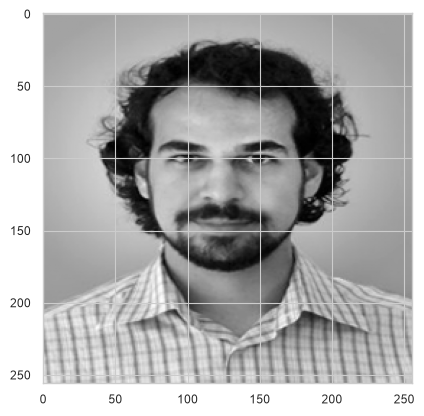

In [16]:
from lib.inpainting import *

image = load("lib/alp.jpg") 

With this image in hand, let us subsample it and try to reconstruct the original.

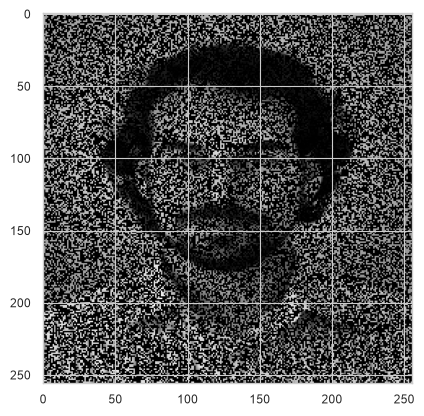

In [17]:
subsampled = show_subsampled(image)

For the rest of the questions, to ensure the function is 
$\mu$-strongly convex, we need to add an $\ell_2$ regularization term to it. As a result, we change the definition of $f_{\ell_1}(\mathbf{\alpha})$ as follows:
$$
    f_{\ell_1}(\mathbf{\alpha}) = \frac{1}{2}\|\mathbf{b} - \mathbf{P}_{\Omega} \mathbf{W}^T\mathbf{\alpha} \|_2^2 + \frac{1}{2}\mu \|\mathbf{\alpha}\|_2^2 
    $$

and the composite function becomes:
 $$
    \min_{\mathbf{\alpha} \in \mathbb{R}^{p}} \underbrace{ \frac{1}{2}\|\mathbf{b} - \mathbf{P}_{\Omega} \mathbf{W}^T\mathbf{\alpha} \|_2^2 + \frac{1}{2}\mu \|\mathbf{\alpha}\|_2^2 }_{f_{\ell_1}(\mathbf{\alpha})} + \underbrace{\lambda_{\ell_1} \|\mathbf{\alpha}\|_1}_{g_{\ell_1}(\mathbf{\alpha})},
    $$

By adding this regularization, we ensure better properties for optimization, making the solution more stable and well-behaved.

In the following cells we will define the optimization problems we need to solve to perform the reconstruction.

- We provide you with a function `P` that acts like the matrix $\mathbf{P}_{\Omega}$. That is, given a vector `x`, it returns a subsampled vector `P(x)` that corresponds to $\mathbf{P}_{\Omega} \mathbf{x}$. We also give you `P_T` which acts like $\mathbf{P}^\top$.
- We provide you with a function `W` and `W_T` that act like the matrix $\mathbf{W}$ and $\mathbf{W^\top}$ respectively. That is, for a vector `x`, `W(x)` and `W_T(x)` return $\mathbf{W}\mathbf{x}$ and $\mathbf{W^\top}\mathbf{x}$ respectively.

__(a)__ (1 point) Using these provided functions, define the observed variable `b` in the cell below.

In [18]:
from lib.inpainting import P, P_T, W, W_T

x = image.reshape(-1) #flattened image

b = P(x).astype(float)  # b = P_Omega x : the observed pixels (cast to float to avoid uint8 arithmetic later)

__(b)__ (1 point) Now define the function `f_l1` as described earlier in the problem text.

In [19]:
mu = 1e-4 # Desired strong convexity of f
def f_l1(alpha):
    residual = b - P(W_T(alpha))          # b - P_Omega W^T alpha
    return 0.5 * np.sum(residual ** 2) + 0.5 * mu * np.sum(alpha ** 2)

__(c)__ (1 point) Write the gradient of $f_{\ell_1}(\mathbf{\alpha})$.

Let $\mathbf A:=\mathbf P_\Omega\mathbf W^\top$, so $f_{\ell_1}(\boldsymbol\alpha)=\tfrac12\|\mathbf b-\mathbf A\boldsymbol\alpha\|_2^2+\tfrac\mu2\|\boldsymbol\alpha\|_2^2$.

Expanding the squared norm,
$$
f_{\ell_1}(\boldsymbol\alpha)=\tfrac12\boldsymbol\alpha^\top\mathbf A^\top\mathbf A\,\boldsymbol\alpha-\mathbf b^\top\mathbf A\boldsymbol\alpha+\tfrac12\|\mathbf b\|_2^2+\tfrac\mu2\boldsymbol\alpha^\top\boldsymbol\alpha .
$$
Using $\nabla_{\boldsymbol\alpha}\big(\tfrac12\boldsymbol\alpha^\top\mathbf Q\boldsymbol\alpha\big)=\mathbf Q\boldsymbol\alpha$ for symmetric $\mathbf Q$ and $\nabla_{\boldsymbol\alpha}(\mathbf c^\top\boldsymbol\alpha)=\mathbf c$,
$$
\nabla f_{\ell_1}(\boldsymbol\alpha)=\mathbf A^\top\mathbf A\boldsymbol\alpha-\mathbf A^\top\mathbf b+\mu\boldsymbol\alpha=\mathbf A^\top(\mathbf A\boldsymbol\alpha-\mathbf b)+\mu\boldsymbol\alpha .
$$
Since $\mathbf A^\top=(\mathbf P_\Omega\mathbf W^\top)^\top=\mathbf W\mathbf P_\Omega^\top$,
$$
\boxed{\nabla f_{\ell_1}(\boldsymbol\alpha)=\mathbf W\mathbf P_\Omega^\top\big(\mathbf P_\Omega\mathbf W^\top\boldsymbol\alpha-\mathbf b\big)+\mu\boldsymbol\alpha}
$$

In [20]:
def grad_f_l1(alpha):
    residual = P(W_T(alpha)) - b          # P_Omega W^T alpha - b
    return W(P_T(residual)) + mu * alpha  # W P_Omega^T (P_Omega W^T alpha - b) + mu alpha

__(d)__ (1 points) Find the Lipschitz constant of $\nabla_\mathbf{\alpha} f_{\ell_1}(\mathbf{\alpha})$ analytically and fill it in the cell below. 

**Answer to (d):**

The Lipschitz constant $L$ of $\nabla f_{\ell_1}$ is the smallest $L$ such that $\|\nabla f_{\ell_1}(\boldsymbol\alpha)-\nabla f_{\ell_1}(\boldsymbol\alpha')\|_2\le L\|\boldsymbol\alpha-\boldsymbol\alpha'\|_2$ for all $\boldsymbol\alpha,\boldsymbol\alpha'$.

With $\mathbf A:=\mathbf P_\Omega\mathbf W^\top$, we have from (c):
$$
\nabla f_{\ell_1}(\boldsymbol\alpha)=\mathbf A^\top(\mathbf A\boldsymbol\alpha-\mathbf b)+\mu\boldsymbol\alpha=\underbrace{(\mathbf A^\top\mathbf A+\mu\mathbf I)}_{=:\ \mathcal H}\,\boldsymbol\alpha-\mathbf A^\top\mathbf b .
$$
So $\nabla f_{\ell_1}$ is a linear map of $\boldsymbol\alpha$ plus a constant, and $\mathcal H$ is the Hessian $\nabla^2f_{\ell_1}$. The constant terms cancel in a difference:
$$
\nabla f_{\ell_1}(\boldsymbol\alpha)-\nabla f_{\ell_1}(\boldsymbol\alpha')=\mathcal H\,(\boldsymbol\alpha-\boldsymbol\alpha').
$$

**Reminder** For a matrix $\mathcal H$ and a vector $\mathbf v\ne\mathbf 0$, the ratio $\|\mathcal H\mathbf v\|_2/\|\mathbf v\|_2$ tells by which factor $\mathcal H$ stretches the length of $\mathbf v$. The *spectral norm* is the largest of these stretch factors:
$$
\|\mathcal H\|_2:=\max_{\mathbf v\ne\mathbf 0}\frac{\|\mathcal H\mathbf v\|_2}{\|\mathbf v\|_2}.
$$

Since $\|\mathcal H\|_2$ is the *largest* stretch factor, every stretch factor is at most that value, $\|\mathcal H\mathbf v\|_2/\|\mathbf v\|_2\le\|\mathcal H\|_2$, i.e.
$$
\|\mathcal H\mathbf v\|_2\le\|\mathcal H\|_2\,\|\mathbf v\|_2\qquad\text{for every }\mathbf v .
$$
This is the matrix analogue of $|hv|\le|h|\,|v|$ for a number $h$.

We have:
$$
\|\nabla f_{\ell_1}(\boldsymbol\alpha)-\nabla f_{\ell_1}(\boldsymbol\alpha')\|_2=\|\mathcal H(\boldsymbol\alpha-\boldsymbol\alpha')\|_2\le\|\mathcal H\|_2\,\|\boldsymbol\alpha-\boldsymbol\alpha'\|_2 .
$$
So, $\|\mathcal H\|_2$ is a valid Lipschitz constant.

It is also the smallest one. Take $\boldsymbol\alpha-\boldsymbol\alpha'$ equal to a direction $\mathbf v^\star$ that is stretched the most, i.e. that attains the maximum in the definition. Then $\|\mathcal H\mathbf v^\star\|_2=\|\mathcal H\|_2\|\mathbf v^\star\|_2$, so the inequality is an equality, and no smaller constant can work. Hence
$$
L=\|\mathcal H\|_2 .
$$

Recall $\mathcal H=\mathbf A^\top\mathbf A+\mu\mathbf I$.

*(a) $\mathcal H$ is symmetric:* 

$(\mathbf A^\top\mathbf A)^\top=\mathbf A^\top\mathbf A$ and $\mathbf I^\top=\mathbf I$, so $\mathcal H^\top=\mathcal H$. A symmetric matrix has an orthonormal basis of eigenvectors $\mathbf u_1,\dots,\mathbf u_p$, with real eigenvalues $\lambda_1,\dots,\lambda_p$ (spectral theorem).

*(b) All eigenvalues of $\mathcal H$ are $\ge\mu>0$:* 

Let $\mathcal H\mathbf u=\lambda\mathbf u$ with $\|\mathbf u\|_2=1$. Multiplying on the left by $\mathbf u^\top$ gives
$$
\mathbf u^\top\mathcal H\mathbf u=\lambda\,\mathbf u^\top\mathbf u=\lambda .
$$
On the other hand, for any vector $\mathbf v$,
$$
\mathbf v^\top\mathcal H\mathbf v=\mathbf v^\top\mathbf A^\top\mathbf A\mathbf v+\mu\,\mathbf v^\top\mathbf v=\|\mathbf A\mathbf v\|_2^2+\mu\|\mathbf v\|_2^2\ \ge\ \mu\|\mathbf v\|_2^2 ,
$$
because a squared norm is nonnegative. Taking $\mathbf v=\mathbf u$ yields $\lambda\ge\mu>0$. Therefore, all eigenvalues of $\mathcal H$ are $\ge\mu>0$, and H is symmetric positive semidefinite.

*(c) The largest stretch factor of $\mathcal H$ is its largest eigenvalue:* 

For a symmetric positive semidefinite matrix, the spectral norm equals the largest eigenvalue (standard fact: in an orthonormal eigenbasis, $\mathcal H$ stretches the component along $\mathbf u_i$ by $\lambda_i\ge0$, so the largest stretch factor is $\lambda_{\max}$). Hence $\|\mathcal H\|_2=\lambda_{\max}(\mathcal H)$.

*(d)* If $\mathbf A^\top\mathbf A\mathbf v=\lambda\mathbf v$, then $\mathcal H\mathbf v=\mathbf A^\top\mathbf A\mathbf v+\mu\mathbf v=(\lambda+\mu)\mathbf v$. So $\mathcal H$ has the same eigenvectors as $\mathbf A^\top\mathbf A$, with every eigenvalue shifted by $+\mu$; in particular the largest one is shifted too. Therefore
$$
L=\lambda_{\max}(\mathcal H)=\lambda_{\max}(\mathbf A^\top\mathbf A)+\mu,\qquad \mathbf A^\top\mathbf A=\mathbf W\mathbf P_\Omega^\top\mathbf P_\Omega\mathbf W^\top ,
$$
and it remains to compute $\lambda_{\max}(\mathbf A^\top\mathbf A)$.

**The eigenvalues of $\mathbf A^\top\mathbf A$.**

*(a) The matrix $\mathbf D:=\mathbf P_\Omega^\top\mathbf P_\Omega$.* $\mathbf P_\Omega\in\mathbb R^{n\times p}$ keeps the $n$ observed pixels, i.e. each row has a single $1$ at an observed position. Hence $\mathbf P_\Omega^\top\mathbf P_\Omega$ is the *diagonal* matrix with a $1$ at each observed pixel and a $0$ at each missing one. The eigenvalues of a diagonal matrix are its diagonal entries, so $\mathbf D$ has eigenvalue $1$ (multiplicity $n\ge1$) and $0$ (multiplicity $p-n>0$).

*(b) $\mathbf W\mathbf D\mathbf W^\top$ has the same eigenvalues as $\mathbf D$.*

Let $\mathbf u$ be an eigenvector of $\mathbf D$ with eigenvalue $\lambda$, i.e. $\mathbf D\mathbf u=\lambda\mathbf u$. Apply $\mathbf W\mathbf D\mathbf W^\top$ to the rotated vector $\mathbf W\mathbf u$:
$$
(\mathbf W\mathbf D\mathbf W^\top)(\mathbf W\mathbf u)
=\mathbf W\mathbf D\underbrace{(\mathbf W^\top\mathbf W)}_{=\mathbf I}\mathbf u
=\mathbf W(\mathbf D\mathbf u)
=\mathbf W(\lambda\mathbf u)
=\lambda\,(\mathbf W\mathbf u).
$$
Since $\mathbf W$ is orthonormal thus preserve lengths and $\mathbf u\neq\mathbf 0$ since it's an eigenvector of $\mathbf D$, $\mathbf W\mathbf u\neq\mathbf 0$, so $\mathbf W\mathbf u$ is an eigenvector of $\mathbf W\mathbf D\mathbf W^\top$ with the *same* eigenvalue $\lambda$.

We showed that every eigenvalue of $\mathbf D$ is an eigenvalue of $\mathbf W\mathbf D\mathbf W^\top$. Conversely, $\mathbf D=\mathbf W^\top(\mathbf W\mathbf D\mathbf W^\top)\mathbf W$ and $\mathbf W^\top$ is also orthonormal, so the same argument applied with $\mathbf W^\top$ in place of $\mathbf W$ shows that every eigenvalue of $\mathbf W\mathbf D\mathbf W^\top$ is an eigenvalue of $\mathbf D$. Hence the two matrices have the same eigenvalues.

*(c) Conclusion:* $\mathbf A^\top\mathbf A=\mathbf W\mathbf D\mathbf W^\top$ has eigenvalues exactly $\{0,1\}$, so $\lambda_{\max}(\mathbf A^\top\mathbf A)=1$ and, thus:
$$
\boxed{L=1+\mu}.
$$

The same argument gives $\lambda_{\min}(\mathcal H)=0+\mu=\mu$, so $\mu\mathbf I\preceq\nabla^2f_{\ell_1}\preceq(1+\mu)\mathbf I$: $f_{\ell_1}$ is $\mu$-strongly convex and its gradient is $(1+\mu)$-Lipschitz, with condition number $\kappa=(1+\mu)/\mu\approx10^4$ for $\mu=10^{-4}$.

In [21]:
lips_grad_f_l1 = 1.0 + mu  # L = lambda_max(W P^T P W^T) + mu = 1 + mu

We have all the necessary ingredients to define the smooth part of our composite objective:

In [22]:
f_l1 = Function(f = f_l1, grad=grad_f_l1, lips_grad = lips_grad_f_l1, strng_cvx=mu)

For the non-smooth term, `l1` represents the unweighted $\ell_1$ norm. `Regularizer` applies the weight `lmda` to both the function value and its proximal operator, reusing `l1_prox` with $\beta=1$:

In [23]:
l1 = Function(f = lambda x: np.sum(np.abs(x), axis=0), prox=lambda gamma, z: l1_prox(gamma, z, beta=1))

g_l1 = Regularizer(l1)

In [24]:
composite_objective = CompositeFunction(f=f_l1, g=g_l1)

With the objective defined, we provide you with a function with the following signature:
```python
solve_composite(method: OptAlgorithm, composite_objective: CompositeFunction, lmda: float, max_iterations: int) -> Vector
```

In other words, the function takes an optimization algorithm `method`, a CompositeFunction `composite_objective`, a regularization parameter `lmda` and a number of iterations `max_iterations` and returns a vector which is the last iterate given by the `method`.



In [25]:
from lib.inpainting import solve_composite

__(e)__ (5 points) Using `solve_composite` reconstruct the subsampled image. Recall that the composite problem solves for $\mathbf{\alpha}$ so you need to convert the output back to an image and visualize it.

Select a reasonable value for `lmda`.

**Bonus (2 points).** Using `solve_composite` and the `PSNR` metric, find the best value for `lmda`.

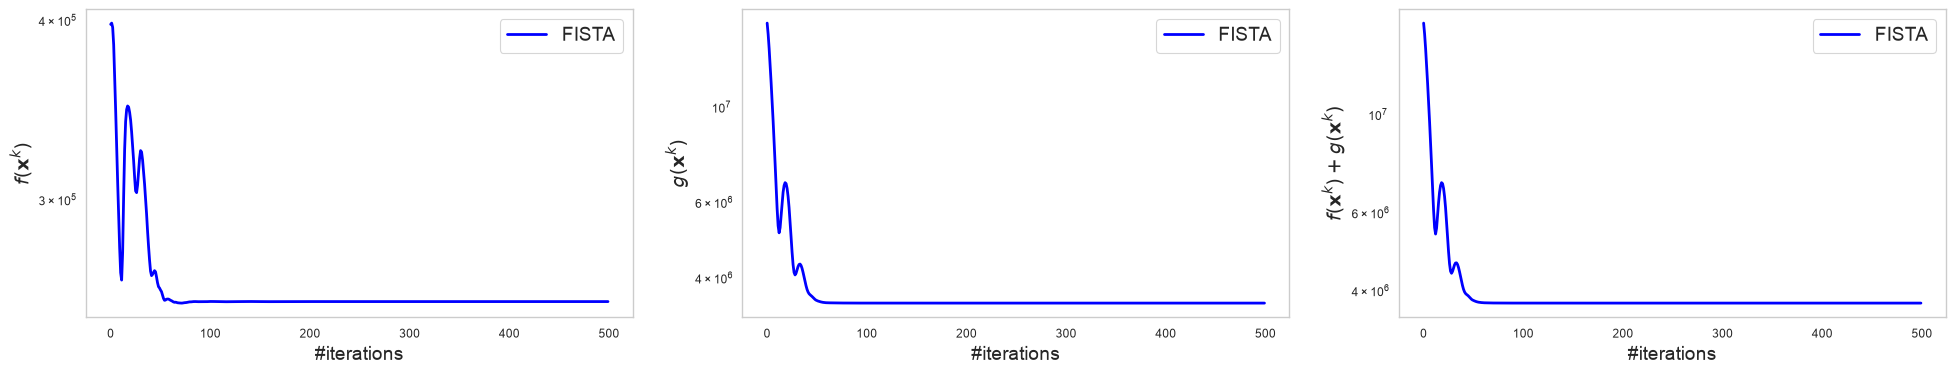

In [26]:
lmda = 4.5  # chosen from the PSNR sweep below (see the bonus cell)
out = solve_composite(FISTA, composite_objective, lmda, max_iterations=500)  # FISTA_mu, 500 iterations
flat_image_out = W_T(out)   # x = W^T alpha
image_out = flat_image_out.reshape(image.shape)

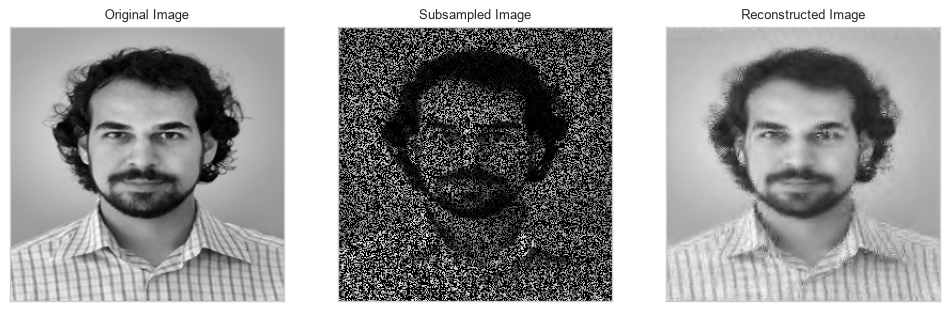

In [27]:
show(true = image, subsampled=subsampled, estimated=image_out)

lmda =   0.1   PSNR = 25.424 dB
lmda =   0.5   PSNR = 26.820 dB
lmda =   1.0   PSNR = 26.986 dB
lmda =   1.5   PSNR = 27.042 dB
lmda =   2.0   PSNR = 27.068 dB
lmda =   2.5   PSNR = 27.079 dB
lmda =   3.0   PSNR = 27.082 dB
lmda =   3.5   PSNR = 27.079 dB
lmda =   4.0   PSNR = 27.064 dB
lmda =   4.5   PSNR = 27.043 dB
lmda =   5.0   PSNR = 27.017 dB
lmda =  10.0   PSNR = 26.553 dB
lmda =  20.0   PSNR = 25.275 dB

Best lmda on the grid: 3  (PSNR = 27.082 dB)


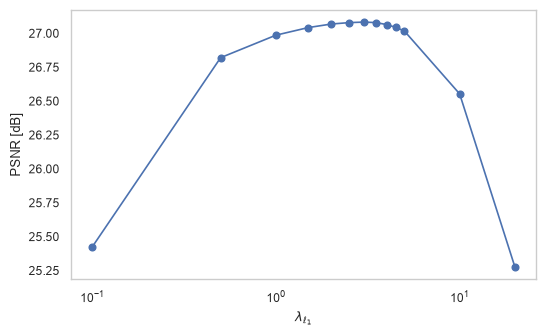

In [28]:
def PSNR(true, estimate, peak=255.0):
    mse = np.mean((true.astype(float) - estimate) ** 2)
    return 10 * np.log10(peak ** 2 / mse)

lmda_grid = [0.1, 0.5, 1, 1.5, 2, 2.5, 3, 3.5,4,4.5, 5, 10, 20]

psnrs = []
for lm in lmda_grid:
    alpha_lm = solve_composite(FISTA, composite_objective, lm, max_iterations=500)
    plt.close("all")  # suppresses the convergence plots that solve_composite draws on each call.
    psnrs.append(PSNR(image, W_T(alpha_lm).reshape(m, m)))
    print(f"lmda = {lm:5.1f}   PSNR = {psnrs[-1]:.3f} dB")

best_lmda = lmda_grid[int(np.argmax(psnrs))]
print(f"\nBest lmda on the grid: {best_lmda}  (PSNR = {max(psnrs):.3f} dB)")

plt.figure(figsize=(6, 3.5))
plt.semilogx(lmda_grid, psnrs, "o-")
plt.xlabel(r"$\lambda_{\ell_1}$"); plt.ylabel("PSNR [dB]"); plt.grid(); plt.show()


**Discussion of (e) and of the bonus.**

* *Method:* We use FISTA $_\mu$: the problem has $\kappa=(1+\mu)/\mu\approx10^4$, and FISTA $_\mu$ needs $O(\sqrt\kappa\log\varepsilon^{-1})$ iterations versus $O(\kappa\log\varepsilon^{-1})$ for ISTA $_\mu$ (Lecture 7, slide 23), at almost the same cost per iteration (one $\nabla f$, one prox: here $\nabla f$ costs one wavelet transform and one inverse transform, and the prox is a soft-thresholding, $O(p)$). SubG is not used because of its $O(1/\sqrt k)$ rate.

* *Choice of $\lambda_{\ell_1}$:* $\lambda$ trades data fit against sparsity of the wavelet coefficients: If $\lambda$ is too small, the sparsity prior hardly constrains the $60\%$ missing pixels (the data-fit term only involves the observed ones), so the solution stays close to the subsampled image, whose random black pixels act as noise and give a dense wavelet representation (many nonzero coefficients). If it is too large, $\boldsymbol\alpha$ is over-shrunk and the image is blurred and loses detail. The sweep above shows exactly this trade-off, with a flat maximum around $\lambda\approx4.5$ (PSNR $\approx24.537$ dB). Note that PSNR requires the true image, so this tuning is an oracle: in practice one would pick $\lambda$ with a held-out subset of the observed pixels (cross-validation).

* *Result:* While the reconstruction recovers the structure of the image from only $\approx40\%$ of the original pixels, remaining defects are a blur and ringing near sharp edges, as expected from a wavelet-sparsity prior plus $\ell_1$ shrinkage bias.
